In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/thuyduc/home-credit-default-risk-sample/bureau_balance_sample.csv
/kaggle/input/datasets/thuyduc/home-credit-default-risk-sample/HomeCredit_columns_description.csv
/kaggle/input/datasets/thuyduc/home-credit-default-risk-sample/instalments_payments_sample.csv
/kaggle/input/datasets/thuyduc/home-credit-default-risk-sample/POS_CASH_balance_sample.csv
/kaggle/input/datasets/thuyduc/home-credit-default-risk-sample/bureau_sample.csv
/kaggle/input/datasets/thuyduc/home-credit-default-risk-sample/previous_application_sample.csv
/kaggle/input/datasets/thuyduc/home-credit-default-risk-sample/application_train_sample.csv
/kaggle/input/datasets/thuyduc/home-credit-default-risk-sample/credit_card_balance_sample.csv


# Notebook Purpose

Với EDA - Part 1, ta đã kiểm tra missing values từ các cột của các tập dữ liệu và loại bỏ đi những cột có quá nhiều missing values

Ta cũng đã kiểm tra các outliers từ các cột dựa trên box plot

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import matplotlib.ticker as mticker
import math
import itertools
from typing import Literal
from matplotlib.ticker import FuncFormatter
from matplotlib.axes import Axes
from matplotlib.figure import Figure
import seaborn.objects as so

In [4]:
application_train = pd.read_csv('/kaggle/input/datasets/thuyduc/home-credit-default-risk-sample/application_train_sample.csv')
bureau = pd.read_csv('/kaggle/input/datasets/thuyduc/home-credit-default-risk-sample/bureau_sample.csv')
bureau_balance = pd.read_csv('/kaggle/input/datasets/thuyduc/home-credit-default-risk-sample/bureau_balance_sample.csv')
credit_card_balance = pd.read_csv('/kaggle/input/datasets/thuyduc/home-credit-default-risk-sample/credit_card_balance_sample.csv')
installments_payments = pd.read_csv('/kaggle/input/datasets/thuyduc/home-credit-default-risk-sample/instalments_payments_sample.csv')
previous_application = pd.read_csv('/kaggle/input/datasets/thuyduc/home-credit-default-risk-sample/previous_application_sample.csv')
POS_CASH_balance = pd.read_csv('/kaggle/input/datasets/thuyduc/home-credit-default-risk-sample/POS_CASH_balance_sample.csv')

In [5]:
class BarPlot:
    def __init__(self, df:pd.DataFrame):
        self.df = df

    @staticmethod
    def readable_numbers(x: float) -> str:
        """
        takes a large number and formats it into K,M to make it more readable

        Args
            x: float value to format

        Returns
            str: formatted string
        """
        if x >= 1e6:
            s = '{:1.2f}M'.format(x*1e-6)
        else:
            s = '{:1.2f}K'.format(x*1e-3)
        return s
    
    def set_locator(self, axes: Axes):
        """
        Format x, y ticklabels into more readable form

        Args
            axes: matplotlib axes to format x, y ticklabels
        """
        def is_number(x):
            x = x.replace('−', '-')
            try:
                float(x)
                return True
            except ValueError:
                return False
    
        x_ticklabels = [tick.get_text() for tick in axes.get_xticklabels()]
        y_ticklabels = [tick.get_text() for tick in axes.get_yticklabels()]
    
        formatter = FuncFormatter(lambda val, pos: self.readable_numbers(val))

        if is_number(x_ticklabels[0]) == True:
            axes.xaxis.set_major_formatter(formatter)
        if is_number(y_ticklabels[0]) == True:
            axes.yaxis.set_major_formatter(formatter)

    def single_plot(
        self,
        x_axis: str,
        y_axis: str,
        hue: str | None,
        kwarg: dict,
        readable_label: bool = False,
        ax: Axes = None
    ) -> Axes:
        """
        Draw a beautiful and readable bar plot.
    
        Args:
            x_axis: column for x-axis
            y_axis: column for y-axis
            hue: column to group bars (optional)
            readable_label: whether to display readable number labels
            ax: matplotlib axes to draw plot
            kwarg: other keyword arguments (e.g., from seaborn barplot)
        """
    
        # --- Setup Axes ---
        if ax is None:
            ax = plt.gca()
        
        # --- Draw the barplot ---
        if hue is None:
            palette=None
        else:
            palette = sns.color_palette("Spectral", n_colors=self.df[hue].nunique()) if hue else "viridis"
            # or: "rocket", "magma", "coolwarm", "crest", "flare", "viridis"

        bar = sns.barplot(
            data=self.df,
            x=x_axis,
            y=y_axis,
            hue=hue,
            ax=ax,
            palette=palette,
            edgecolor="black",
            linewidth=1.2,
            **kwarg
        )
    
        # --- 🧠 Title & Labels ---
        ax.set_title(
            f'{y_axis} by {x_axis}',
            fontdict={
                'fontsize': 16,
                'fontweight': 'bold',
                # 'fontname': 'Times New Roman'
            },
            pad=15
        )
        ax.set_xlabel(x_axis, fontsize=12, labelpad=10)
        ax.set_ylabel(y_axis, fontsize=12, labelpad=10)
    
        # --- 🎨 Legend ---
        if hue is not None:
            ax.legend(
                title=hue,
                title_fontsize=11,
                fontsize=10,
                loc='best',
                frameon=False
            )
    
        # --- 💬 Bar labels ---
        if readable_label:
            for container in bar.containers:
                labels = [self.readable_numbers(p.get_height()) for p in container]
                bar.bar_label(
                    container,
                    labels=labels,
                    label_type='edge',
                    fontsize=9,
                    # fontname='Times New Roman',
                    color='black',
                    padding=2
                )
            self.set_locator(bar)
    
        # # --- 🌤️ Tighten layout ---
        # plt.tight_layout()
    
        return bar

    def multiple_plots(self, x_axis_list: list[str], y_axis_list: list[str], hue_list: list[str|None], kwarg: dict,
                       plots_each_row: int, readable_label: bool = False) -> tuple[Figure, np.ndarray]:
        """
        Draw multiple plots

        Args
            Same as single_plot
            y_axis_list: list of columns for y axis
            plots_each_row: number of plots for each row in matplotlib figure
            kwarg: other keyword arguments if needed.
        """
        
        combination = list(zip(x_axis_list, y_axis_list, hue_list))
        
        length = len(combination)
        number_rows = math.ceil(length / plots_each_row)
    
        fig, axes = plt.subplots(nrows=number_rows, ncols=plots_each_row, figsize=(20, 8),
                                sharey=True) # same y_axis scale
        axes = np.array(axes).reshape(number_rows, plots_each_row)
    
        coordinates = list(itertools.product(range(number_rows), range(plots_each_row)))
    
        for coor, com in zip(coordinates, combination):
            x, y, hue = com
            ax = axes[coor]
            self.single_plot(
                x_axis=x,
                y_axis=y,
                hue=hue,
                readable_label=readable_label,
                kwarg=kwarg,
                ax=ax
            )
    
        # hide any unused axes
        for coor in coordinates[length:]:
            fig.delaxes(axes[coor])

        return fig, axes

# Kiểm tra missing values

Đầu tiên là loại bỏ đi các cột có quá nhiều missing values trước, chưa cần phải fill missing values liền cho các cột có ít missing values vì ta sẽ cần phải build Data Pipeline để tự động hoá việc này nên sẽ cần phải split train, test trước khi fill missing values

## Kiểm tra Missing Values cho application_train

Text(0.5, 0, 'Columns')

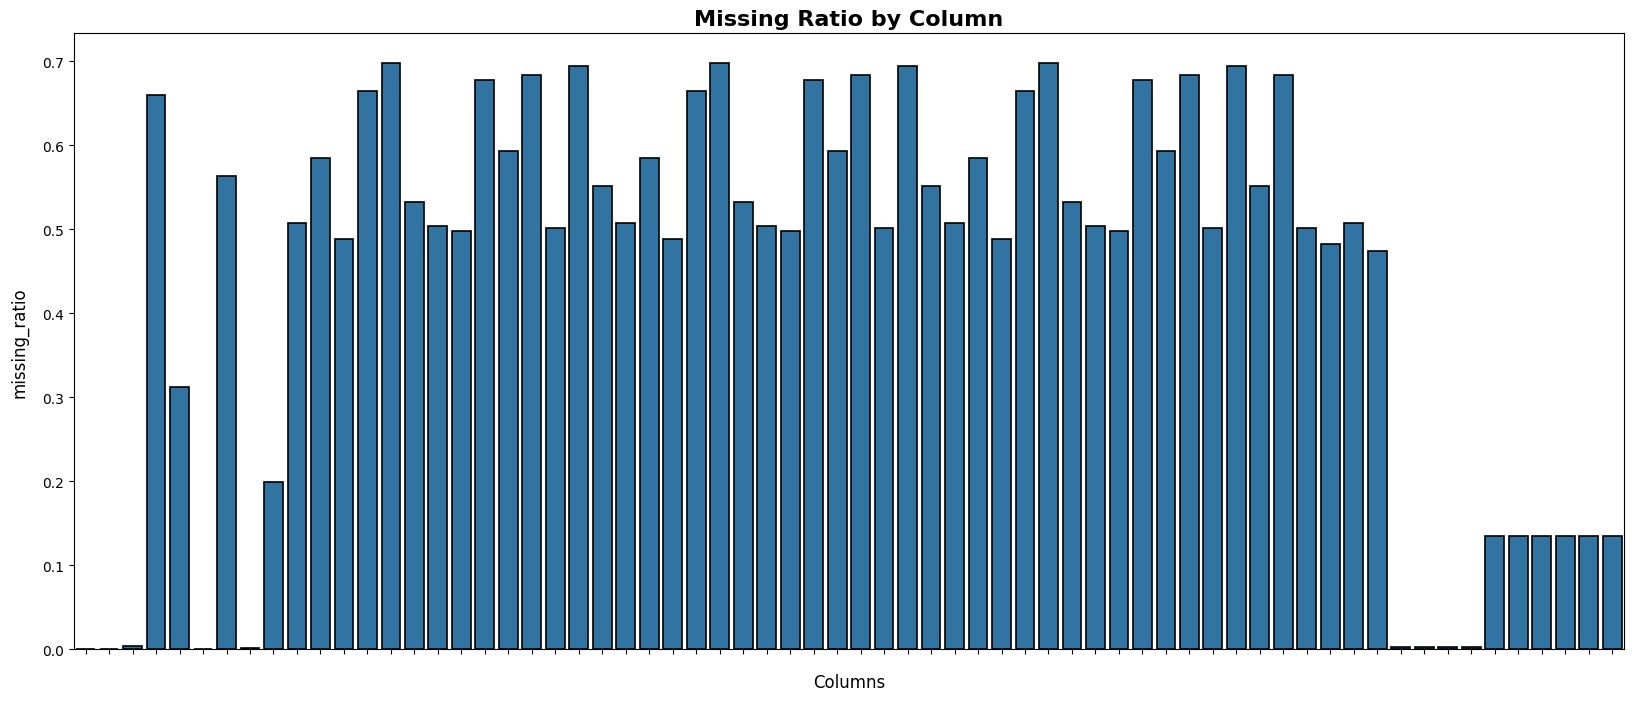

In [6]:
application_train_aggregate = application_train.isnull().sum().astype(float).to_frame()
application_train_aggregate.iloc[:, 0] = application_train_aggregate.iloc[:, 0] / len(application_train)
application_train_aggregate = application_train_aggregate.rename(columns={0: "missing_ratio"})
data = application_train_aggregate[application_train_aggregate['missing_ratio']!=0]
data = data.reset_index()

barplotter = BarPlot(data)

x_axis_list = ['index' for _ in range(1)]
y_axis_list =['missing_ratio']
hue_list = [None for _ in range(1)]
ig, axes = barplotter.multiple_plots(x_axis_list=x_axis_list, y_axis_list=y_axis_list,
                                     hue_list=hue_list, plots_each_row=1, readable_label=False, kwarg={})
axes[0, 0].set_xticklabels([])
axes[0, 0].set_title('Missing Ratio by Column', fontdict={'fontsize': 16, 'fontweight': 'bold'})
axes[0, 0].set_xlabel('Columns')

có nhiều cột có rất nhiều mising values, đây sẽ là những cột bị loại bỏ đi và sẽ tiến hành fill missing values cho những cột có ít missing values

In [7]:
# tìm và loại bỏ các cột có quá nhiều missing values
filter_index = data['missing_ratio'].sort_values(ascending=True).index[:9]
columns_name_keep = data.iloc[filter_index, :]['index'].values
all_columns = data['index'].values
columns_name_remove = set(all_columns) - set(columns_name_keep)
columns_name_remove = list(columns_name_remove)

application_train_filtered = application_train.drop(columns=columns_name_remove)
application_train_filtered.head()

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,TARGET
0,159606,Cash loans,F,N,Y,1,144000.0,264888.0,26329.5,234000.0,...,0,0,0,0,0,0,0,0,0,0
1,253279,Cash loans,F,N,Y,0,270000.0,679500.0,45724.5,679500.0,...,0,0,0,0,0,0,0,0,0,0
2,196211,Cash loans,F,N,Y,0,202500.0,239850.0,22671.0,225000.0,...,0,0,0,0,0,0,0,0,0,0
3,211519,Cash loans,F,N,Y,0,90000.0,454500.0,24345.0,454500.0,...,0,0,0,0,0,0,0,0,0,0
4,444454,Cash loans,F,N,N,0,189000.0,590337.0,28530.0,477000.0,...,0,0,0,0,0,0,0,0,0,0


## Kiểm tra Missing Values cho bureau

Text(0.5, 0, 'Columns')

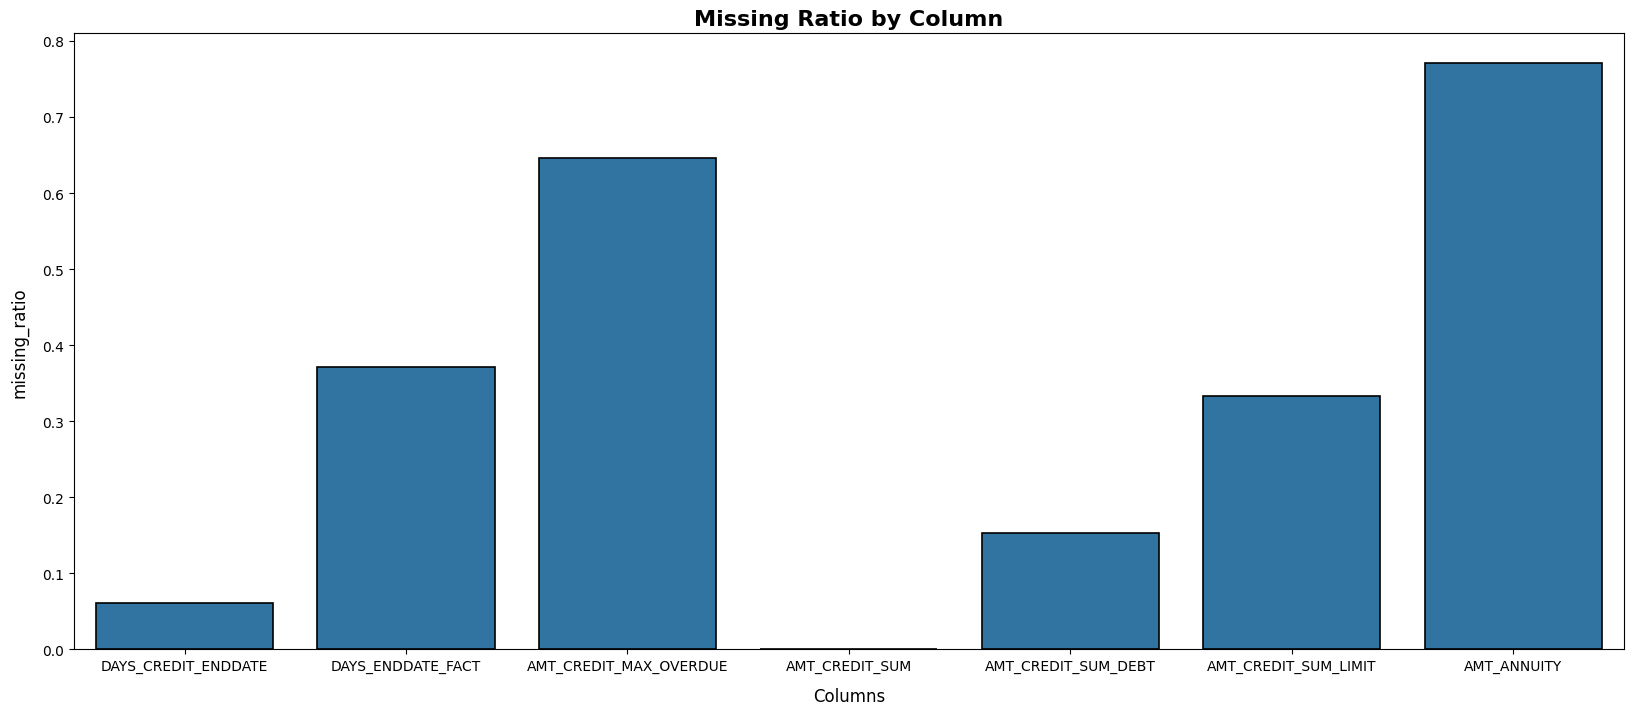

In [8]:
bureau_aggregate = bureau.isnull().sum().astype(float).to_frame()
bureau_aggregate.iloc[:, 0] = bureau_aggregate.iloc[:, 0] / len(bureau)
bureau_aggregate = bureau_aggregate.rename(columns={0: "missing_ratio"})
data = bureau_aggregate[bureau_aggregate['missing_ratio']!=0]
data = data.reset_index()

barplotter = BarPlot(data)

x_axis_list = ['index' for _ in range(1)]
y_axis_list =['missing_ratio']
hue_list = [None for _ in range(1)]
ig, axes = barplotter.multiple_plots(x_axis_list=x_axis_list, y_axis_list=y_axis_list,
                                     hue_list=hue_list, plots_each_row=1, readable_label=False, kwarg={})
axes[0, 0].set_title('Missing Ratio by Column', fontdict={'fontsize': 16, 'fontweight': 'bold'})
axes[0, 0].set_xlabel('Columns')

Có 2 cột có missing_ratio nhỏ hơn 0.1 nên sẽ giữ lại 2 cột này và loại bỏ các cột còn lại

In [9]:
# tìm và loại bỏ các cột có quá nhiều missing values
filter_index = data['missing_ratio'].sort_values(ascending=True).index[:2]
columns_name_keep = data.iloc[filter_index, :]['index'].values
all_columns = data['index'].values
columns_name_remove = set(all_columns) - set(columns_name_keep)
columns_name_remove = list(columns_name_remove)

bureau_filtered = bureau.drop(columns=columns_name_remove)
bureau_filtered.head()

,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_OVERDUE,CREDIT_TYPE,DAYS_CREDIT_UPDATE
0,136226,5714502,Active,currency 1,-521,0,551.0,0,112500.0,0.0,Credit card,-30
1,136226,5714503,Closed,currency 1,-559,0,NaN,0,110250.0,0.0,Credit card,-351
2,435112,5714512,Closed,currency 1,-1412,0,-861.0,0,85288.5,0.0,Consumer credit,-753
3,435112,5714513,Closed,currency 1,-1590,0,-1344.0,0,100129.5,0.0,Consumer credit,-783
4,435112,5714514,Closed,currency 1,-1181,0,-875.0,0,44419.5,0.0,Consumer credit,-872


## Kiểm tra Missing Values cho bureau_balance

In [10]:
bureau_balance.isnull().sum()

SK_ID_BUREAU      0
MONTHS_BALANCE    0
STATUS            0
dtype: int64

Tập dữ liệu này không có bất kỳ missing values nào

## Kiểm tra Missing Values cho credit_card_balance

Text(0.5, 0, 'Columns')

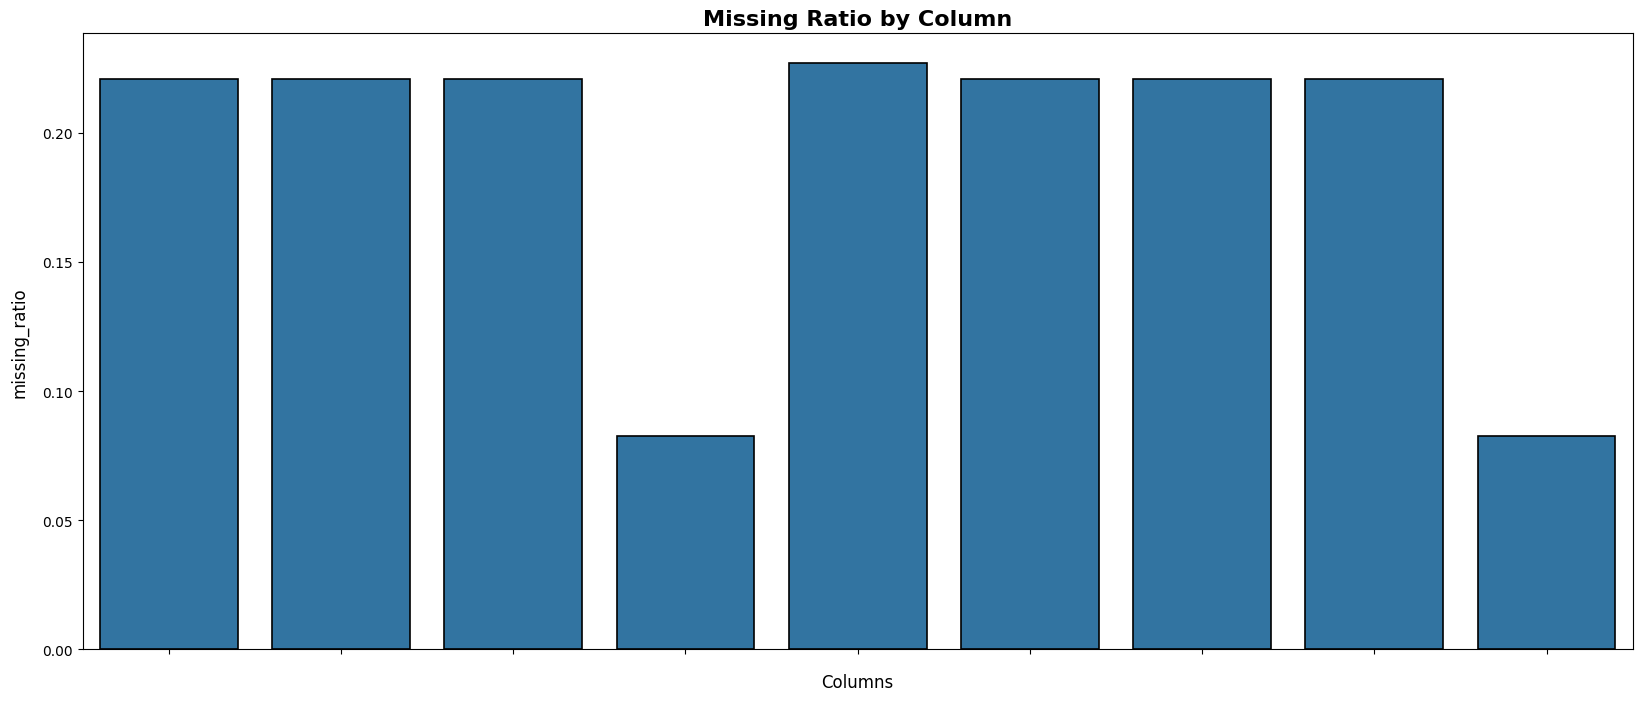

In [11]:
credit_card_balance_aggregate = credit_card_balance.isnull().sum().astype(float).to_frame()
credit_card_balance_aggregate.iloc[:, 0] = credit_card_balance_aggregate.iloc[:, 0] / len(credit_card_balance)
credit_card_balance_aggregate = credit_card_balance_aggregate.rename(columns={0: "missing_ratio"})
data = credit_card_balance_aggregate[credit_card_balance_aggregate['missing_ratio']!=0]
data = data.reset_index()

barplotter = BarPlot(data)

x_axis_list = ['index' for _ in range(1)]
y_axis_list =['missing_ratio']
hue_list = [None for _ in range(1)]
ig, axes = barplotter.multiple_plots(x_axis_list=x_axis_list, y_axis_list=y_axis_list,
                                     hue_list=hue_list, plots_each_row=1, readable_label=False, kwarg={})
axes[0, 0].set_xticklabels([])
axes[0, 0].set_title('Missing Ratio by Column', fontdict={'fontsize': 16, 'fontweight': 'bold'})
axes[0, 0].set_xlabel('Columns')

giữ lại 2 cột có missing values nhỏ hơn 0.1

In [12]:
# tìm và loại bỏ các cột có quá nhiều missing values
filter_index = data['missing_ratio'].sort_values(ascending=True).index[:2]
columns_name_keep = data.iloc[filter_index, :]['index'].values
all_columns = data['index'].values
columns_name_remove = set(all_columns) - set(columns_name_keep)
columns_name_remove = list(columns_name_remove)

credit_card_balance_filtered = credit_card_balance.drop(columns=columns_name_remove)
credit_card_balance_filtered.head()

,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,AMT_BALANCE,AMT_CREDIT_LIMIT_ACTUAL,AMT_DRAWINGS_CURRENT,AMT_INST_MIN_REGULARITY,AMT_PAYMENT_TOTAL_CURRENT,AMT_RECEIVABLE_PRINCIPAL,AMT_RECIVABLE,AMT_TOTAL_RECEIVABLE,CNT_DRAWINGS_CURRENT,CNT_INSTALMENT_MATURE_CUM,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,1864742,303581,-1,0.000,45000,0.0,0.000,0.0,0.00,0.000,0.000,0,59.0,Active,0,0
1,2037377,289902,-1,131294.340,135000,0.0,6774.660,6975.0,128518.02,131294.340,131294.340,0,11.0,Active,0,0
2,2016842,302450,-3,0.000,0,0.0,0.000,0.0,0.00,0.000,0.000,0,2.0,Completed,0,0
3,1288249,406607,-4,0.000,270000,0.0,0.000,0.0,0.00,0.000,0.000,0,80.0,Active,0,0
4,2043751,441030,-4,436537.755,450000,4500.0,23238.585,23400.0,421431.93,435192.255,435192.255,1,26.0,Active,0,0


## Kiểm tra Missing Values cho installments_payments

Text(0.5, 0, 'Columns')

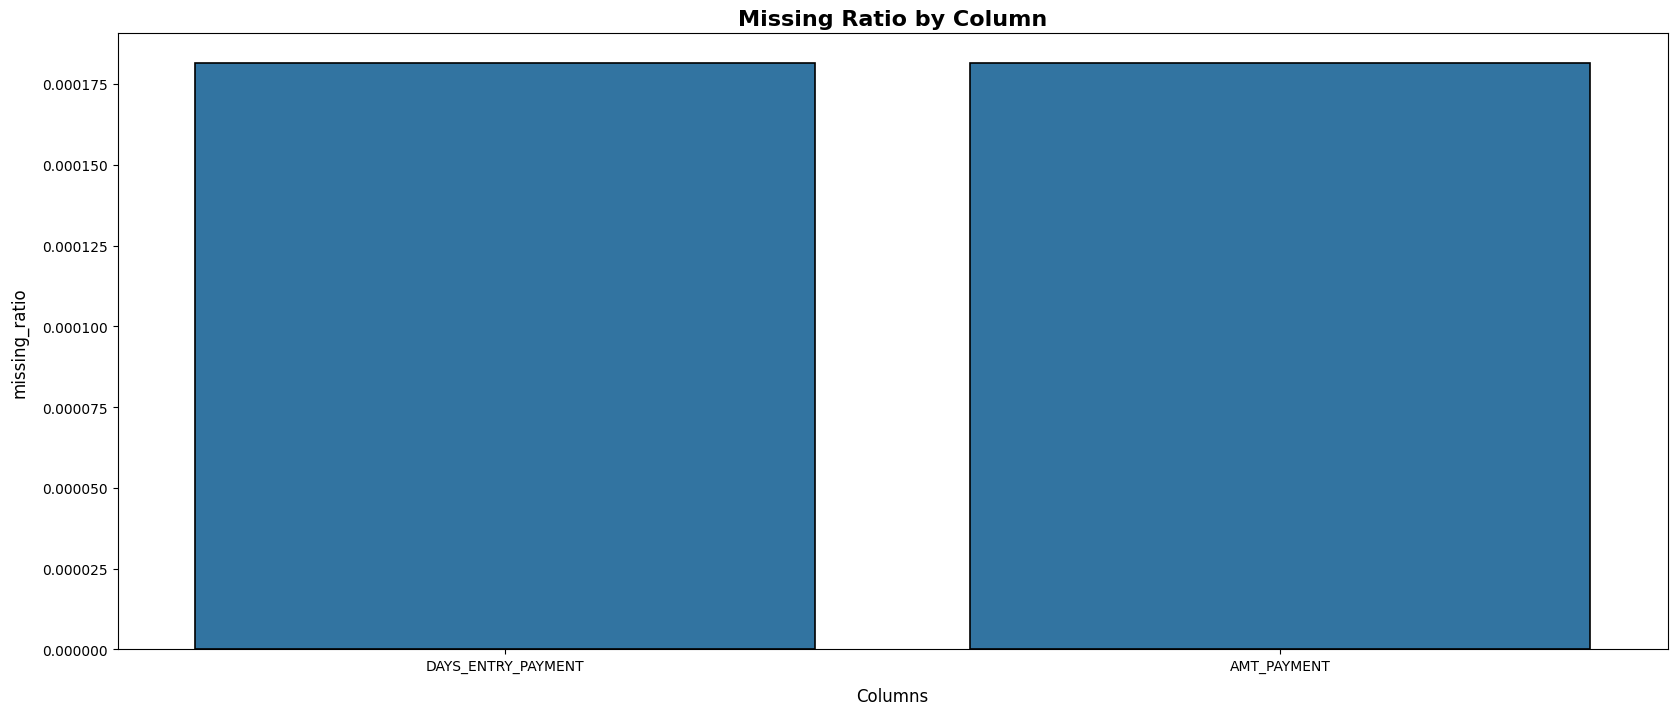

In [13]:
installments_payments_aggregate = installments_payments.isnull().sum().astype(float).to_frame()
installments_payments_aggregate.iloc[:, 0] = installments_payments_aggregate.iloc[:, 0] / len(installments_payments)
installments_payments_aggregate = installments_payments_aggregate.rename(columns={0: "missing_ratio"})
data = installments_payments_aggregate[installments_payments_aggregate['missing_ratio']!=0]
data = data.reset_index()

barplotter = BarPlot(data)

x_axis_list = ['index' for _ in range(1)]
y_axis_list =['missing_ratio']
hue_list = [None for _ in range(1)]
ig, axes = barplotter.multiple_plots(x_axis_list=x_axis_list, y_axis_list=y_axis_list,
                                     hue_list=hue_list, plots_each_row=1, readable_label=False, kwarg={})
axes[0, 0].set_title('Missing Ratio by Column', fontdict={'fontsize': 16, 'fontweight': 'bold'})
axes[0, 0].set_xlabel('Columns')

Chỉ có 2 cột có missing values với missing_ratio đều nhỏ hơn 0.1 -> giữ lại cả 2 cột

In [14]:
installments_payments_filtered = installments_payments.copy()
installments_payments_filtered.head()

,SK_ID_PREV,SK_ID_CURR,NUM_INSTALMENT_VERSION,NUM_INSTALMENT_NUMBER,DAYS_INSTALMENT,DAYS_ENTRY_PAYMENT,AMT_INSTALMENT,AMT_PAYMENT
0,1054186,161674,1.0,6,-1180.0,-1187.0,6948.360,6948.360
1,2234264,184693,4.0,11,-349.0,-352.0,29432.295,29432.295
2,1594684,100193,0.0,56,-1153.0,-1153.0,301.860,301.860
3,2260765,106012,3.0,23,-56.0,-59.0,13494.915,13494.915
4,1720935,176364,1.0,9,-354.0,-356.0,61192.530,61192.530


## Kiểm tra Missing Values cho previous_application

Text(0.5, 0, 'Columns')

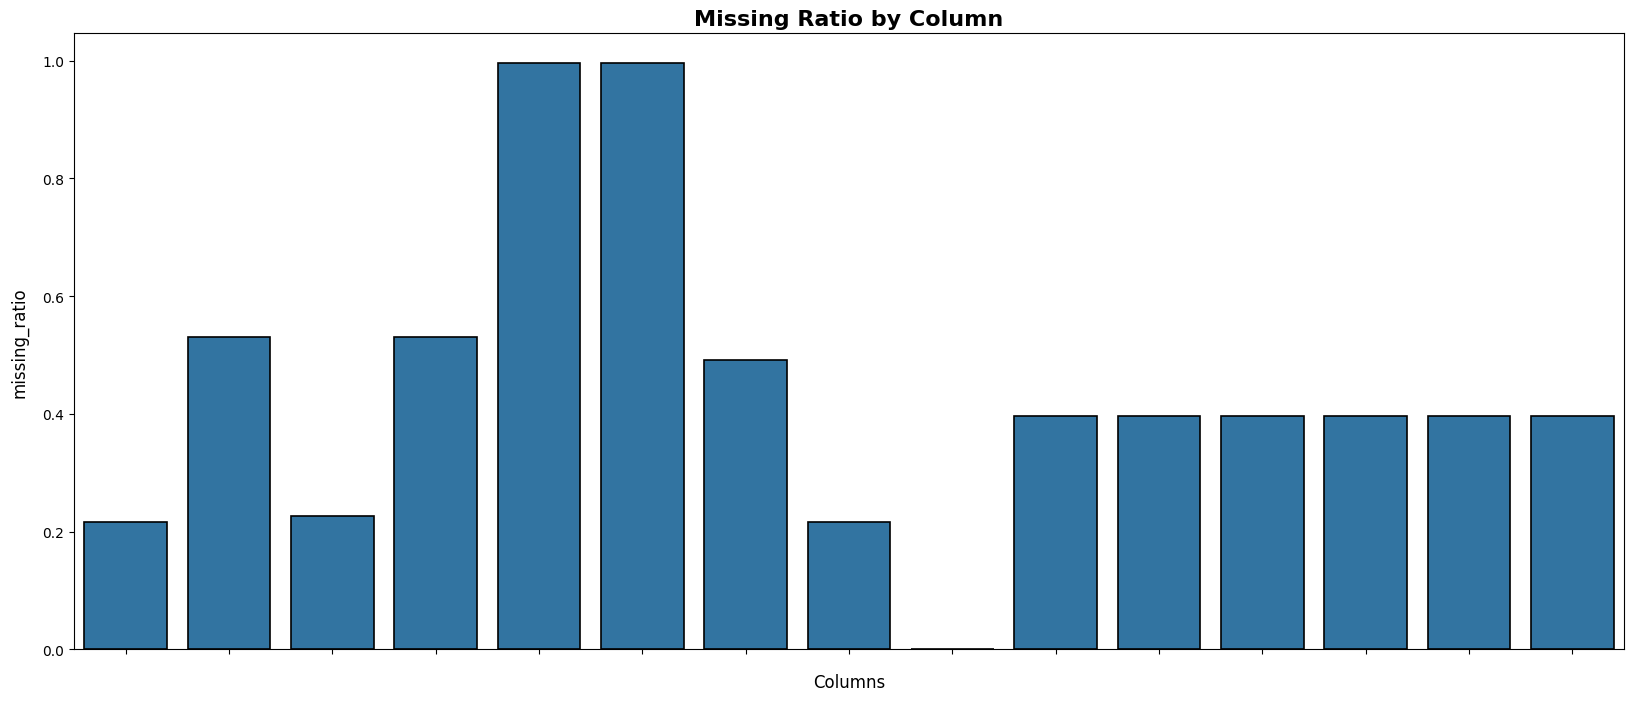

In [15]:
previous_application_aggregate = previous_application.isnull().sum().astype(float).to_frame()
previous_application_aggregate.iloc[:, 0] = previous_application_aggregate.iloc[:, 0] / len(previous_application)
previous_application_aggregate = previous_application_aggregate.rename(columns={0: "missing_ratio"})
data = previous_application_aggregate[previous_application_aggregate['missing_ratio']!=0]
data = data.reset_index()

barplotter = BarPlot(data)

x_axis_list = ['index' for _ in range(1)]
y_axis_list =['missing_ratio']
hue_list = [None for _ in range(1)]
ig, axes = barplotter.multiple_plots(x_axis_list=x_axis_list, y_axis_list=y_axis_list,
                                     hue_list=hue_list, plots_each_row=1, readable_label=False, kwarg={})
axes[0, 0].set_xticklabels([])
axes[0, 0].set_title('Missing Ratio by Column', fontdict={'fontsize': 16, 'fontweight': 'bold'})
axes[0, 0].set_xlabel('Columns')

Giữ lại 1 cột có missing_ratio < 0.1

In [16]:
# tìm và loại bỏ các cột có quá nhiều missing values
filter_index = data['missing_ratio'].sort_values(ascending=True).index[:1]
columns_name_keep = data.iloc[filter_index, :]['index'].values
all_columns = data['index'].values
columns_name_remove = set(all_columns) - set(columns_name_keep)
columns_name_remove = list(columns_name_remove)

previous_application_filtered = previous_application.drop(columns=columns_name_remove)
previous_application_filtered.head()

,SK_ID_PREV,SK_ID_CURR,NAME_CONTRACT_TYPE,AMT_APPLICATION,AMT_CREDIT,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,FLAG_LAST_APPL_PER_CONTRACT,NFLAG_LAST_APPL_IN_DAY,NAME_CASH_LOAN_PURPOSE,...,CODE_REJECT_REASON,NAME_CLIENT_TYPE,NAME_GOODS_CATEGORY,NAME_PORTFOLIO,NAME_PRODUCT_TYPE,CHANNEL_TYPE,SELLERPLACE_AREA,NAME_SELLER_INDUSTRY,NAME_YIELD_GROUP,PRODUCT_COMBINATION
0,2523466,122040,Cash loans,112500.0,136444.5,TUESDAY,11,Y,1,XNA,...,XAP,Repeater,XNA,Cash,x-sell,Credit and cash offices,-1,XNA,high,Cash X-Sell: high
1,2315218,175704,Cash loans,0.0,0.0,TUESDAY,11,Y,1,XNA,...,XAP,Repeater,XNA,XNA,XNA,Credit and cash offices,-1,XNA,XNA,Cash
2,2257824,161140,Cash loans,211500.0,246397.5,FRIDAY,10,Y,1,XNA,...,XAP,Repeater,XNA,Cash,x-sell,Credit and cash offices,-1,XNA,middle,Cash X-Sell: middle
3,1232483,151612,Consumer loans,126490.5,119853.0,TUESDAY,7,Y,1,XAP,...,XAP,New,Auto Accessories,POS,XNA,Regional / Local,130,Industry,low_normal,POS other with interest
4,1583704,315664,Cash loans,0.0,0.0,WEDNESDAY,15,Y,1,XNA,...,HC,Repeater,XNA,XNA,XNA,Credit and cash offices,-1,XNA,XNA,Cash


## Kiểm tra Missing Values cho POS_CASH_balance

Text(0.5, 0, 'Columns')

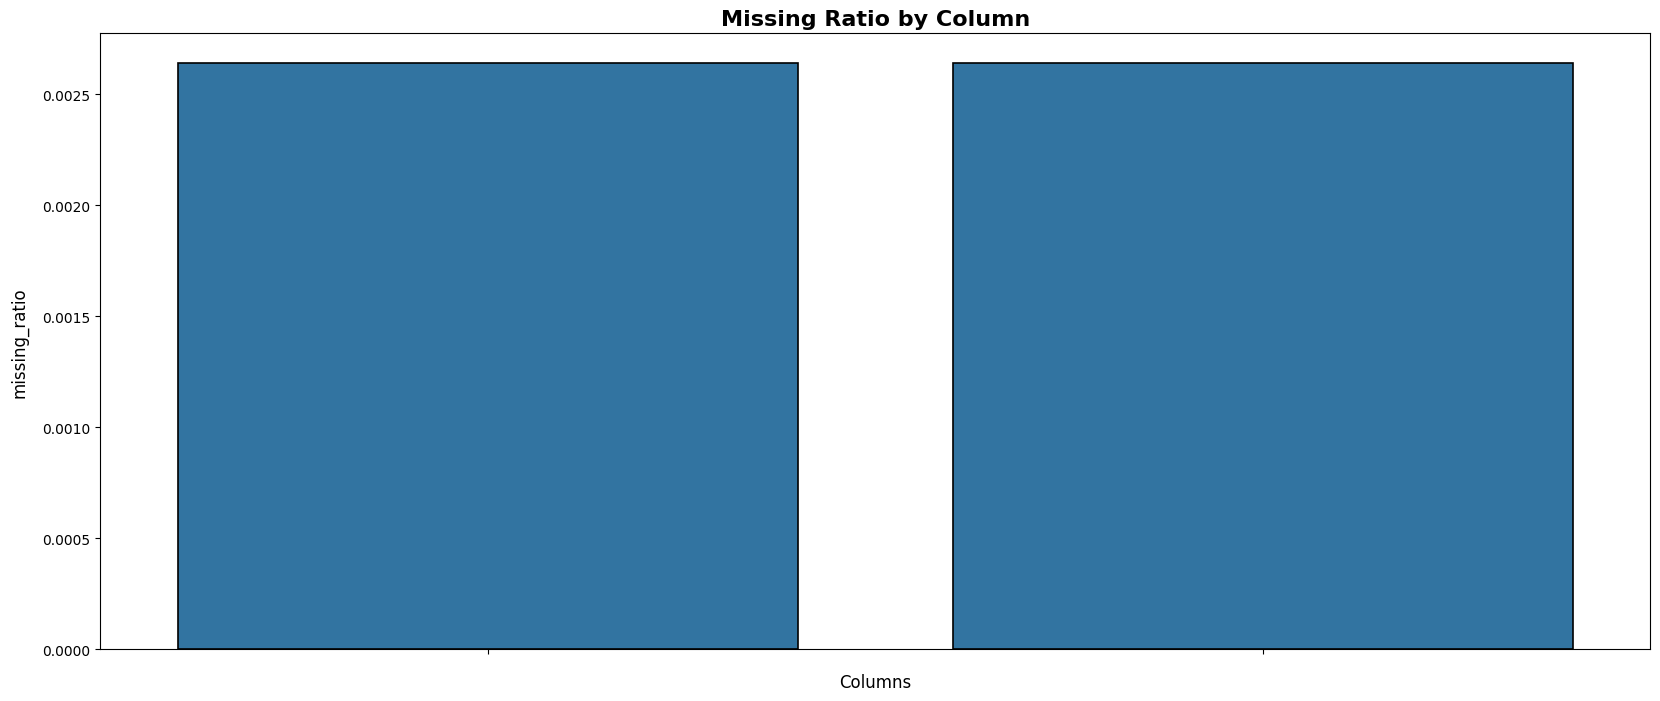

In [17]:
POS_CASH_balance_aggregate = POS_CASH_balance.isnull().sum().astype(float).to_frame()
POS_CASH_balance_aggregate.iloc[:, 0] = POS_CASH_balance_aggregate.iloc[:, 0] / len(POS_CASH_balance)
POS_CASH_balance_aggregate = POS_CASH_balance_aggregate.rename(columns={0: "missing_ratio"})
data = POS_CASH_balance_aggregate[POS_CASH_balance_aggregate['missing_ratio']!=0]
data = data.reset_index()

barplotter = BarPlot(data)

x_axis_list = ['index' for _ in range(1)]
y_axis_list =['missing_ratio']
hue_list = [None for _ in range(1)]
ig, axes = barplotter.multiple_plots(x_axis_list=x_axis_list, y_axis_list=y_axis_list,
                                     hue_list=hue_list, plots_each_row=1, readable_label=False, kwarg={})
axes[0, 0].set_xticklabels([])
axes[0, 0].set_title('Missing Ratio by Column', fontdict={'fontsize': 16, 'fontweight': 'bold'})
axes[0, 0].set_xlabel('Columns')

Giữ lại cả 2 cột vì có missing_ratio < 0.1

In [18]:
POS_CASH_balance_filtered = POS_CASH_balance.copy()
POS_CASH_balance_filtered.head()

,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,CNT_INSTALMENT,CNT_INSTALMENT_FUTURE,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,1803195,182943,-31,48.0,45.0,Active,0,0
1,1784872,397406,-32,12.0,9.0,Active,0,0
2,1110516,204376,-38,48.0,43.0,Active,0,0
3,1387235,153211,-35,36.0,36.0,Active,0,0
4,1846127,380050,-31,36.0,28.0,Active,0,0


# Kiểm tra Outlieurs

In [19]:
class BoxPlot:
    """
    Create single and multiple box plots
    """
    def __init__(self, df: pd.DataFrame):
        self.df = df

    @staticmethod
    def readable_numbers(x: float) -> str:
        """
        takes a large number and formats it into K,M to make it more readable

        Args
            x: float value to format

        Returns
            str: formatted string
        """
        if x >= 1e6:
            s = '{:1.2f}M'.format(x*1e-6)
        else:
            s = '{:1.2f}K'.format(x*1e-3)
        return s

    def set_locator(self, axes: Axes):
        """
        Format x, y ticklabels into more readable form

        Args
            axes: matplotlib axes to format x, y ticklabels
        """
        def is_number(x):
            x = x.replace('−', '-')
            try:
                float(x)
                return True
            except ValueError:
                return False
    
        x_ticklabels = [tick.get_text() for tick in axes.get_xticklabels()]
        y_ticklabels = [tick.get_text() for tick in axes.get_yticklabels()]

        formatter = FuncFormatter(lambda val, pos: self.readable_numbers(val))

        if is_number(x_ticklabels[0]) == True:
            axes.xaxis.set_major_formatter(formatter)
        if is_number(y_ticklabels[0]) == True:
            axes.yaxis.set_major_formatter(formatter)

    def single_plot(
        self,
        x_axis: str,
        y_axis: str | None,
        hue: str | None,
        kwarg: dict | None = None,
        readable_label: bool = False,
        ax: Axes = None
    ) -> Axes:
        """
        Draw a beautiful and readable Box Plot.
    
        Args:
            x_axis: column needed
            y_axis: column needed
            hue: column needed
            dimension: '1d' for single variable, '2d' for grouped boxplot
            readable_label: whether to format x/y tick labels for readability
            ax: matplotlib axes to draw plot
            kwarg: additional seaborn arguments
        """
        
        if ax is None:
            ax = plt.gca()
        if kwarg is None:
            kwarg = {}
            
        # --- Styling palette and defaults ---
        sns.set_style("whitegrid")  # clean background
        palette = kwarg.pop("palette", "Set2") if kwarg else "Set2"
            
        if hue is None:
            palette=None
        
        box = sns.boxplot(
            data=self.df,
            x=x_axis,
            y=y_axis,
            hue=hue,
            ax=ax,
            palette=palette,
            width=0.6,
            fliersize=3,
            linewidth=1.2,
            boxprops={"alpha": 0.8},
            medianprops={"color": "black", "linewidth": 1},
            whiskerprops={"linewidth": 1},
            capprops={"linewidth": 1},
            **kwarg
        )
        
        if y_axis is None:
            y_axis = ""
        
        ax.set_xlabel(x_axis, fontsize=13, labelpad=8)
        ax.set_ylabel(y_axis, fontsize=13, labelpad=8)

        if hue is not None and y_axis != "":
            ax.legend(
                title=hue if hue else "",
                frameon=True,
                fancybox=True,
                framealpha=0.8,
                fontsize=11,
                title_fontsize=12,
                loc="best",
            )
    
        # --- Titles & Ticks ---
        ax.set_title(
            f"Box Plot",
            fontdict={"fontsize": 12, "fontweight": "regular"}, # "fontname": "Times New Roman"
            pad=15
        )
        ax.tick_params(axis="x", labelrotation=0, labelsize=11)
        ax.tick_params(axis="y", labelrotation=0, labelsize=11)
    
        # --- Optional: readable tick labels ---
        if readable_label:
            self.set_locator(ax)
    
        # --- Clean up look ---
        sns.despine(ax=ax, top=True, right=True)
        ax.grid(axis="y", linestyle="--", alpha=0.6)
    
        return box
    
    def multiple_plots(self, y_axis_list: list[str|None], x_axis_list: list[str], kwarg: dict|None,
                       hue_list: list[str|None], plots_each_row: int, 
                       readable_label: bool = False) -> (Figure, np.array([Axes])):
        """
        Draw multiple box plots
        
        Args
            Same as single_plot
            y_axis_list: list of columns for y axis
            plots_each_row: number of plots for each row in matplotlib figure
        """
        combination = list(zip(x_axis_list, y_axis_list, hue_list))
        
        length = len(combination)
        number_rows = math.ceil(length / plots_each_row)
    
        fig, axes = plt.subplots(nrows=number_rows, ncols=plots_each_row, figsize=(16, 8),
                                sharey=True) # same y_axis scale
        axes = np.array(axes).reshape(number_rows, plots_each_row)
    
        coordinates = list(itertools.product(range(number_rows), range(plots_each_row)))
    
        for coor, com in zip(coordinates, combination):
            x, y, hue = com
            ax = axes[coor]
            self.single_plot(
                x_axis=x,
                y_axis=y,
                hue=hue,
                readable_label=readable_label,
                kwarg=kwarg,
                ax=ax
            )
    
        # hide any unused axes
        for coor in coordinates[length:]:
            fig.delaxes(axes[coor])
    
        fig.tight_layout()

        return fig, axes

## Cho application_train

In [20]:
# kiểm tra giá trị ngoại lại cho các cột là có dtype là int64
application_train_int64 = application_train_filtered.select_dtypes(include=['int64'])
application_train_int64 = application_train_int64.drop(columns=['SK_ID_CURR', 'TARGET'])
application_train_int64

# trong application_train_int64 sẽ có một vài cột là dữ liệu nhị phân nên sẽ không có outliers, cần loại bỏ luôn các cột này
binary_cols = [
    col for col in application_train_int64.columns 
    if set(application_train_int64[col].dropna().unique()).issubset({0, 1})
]

all_cols = application_train_int64.columns
nonbinary_cols = list(set(all_cols) - set(binary_cols))

application_train_int64_nonbinary_column = application_train_int64[nonbinary_cols]
application_train_int64_nonbinary_column

# Quan sát thấy: đối với dữ liệu int64 thì các cột thuộc dạng nhị phân chiếm đa số

,DAYS_EMPLOYED,CNT_CHILDREN,REGION_RATING_CLIENT_W_CITY,REGION_RATING_CLIENT,DAYS_ID_PUBLISH,DAYS_BIRTH,HOUR_APPR_PROCESS_START
0,-4833,1,2,2,-2895,-19370,11
1,365243,0,2,2,-4893,-21436,13
2,365243,0,2,2,-4355,-24942,11
3,-5390,0,2,2,-2844,-19377,14
4,-1537,0,2,2,-2830,-14907,15
...,...,...,...,...,...,...,...
61498,-894,0,2,2,-91,-10473,12
61499,-1302,1,1,1,-737,-9755,12
61500,-4189,0,1,3,-4213,-11981,13
61501,365243,0,2,2,-230,-16666,14


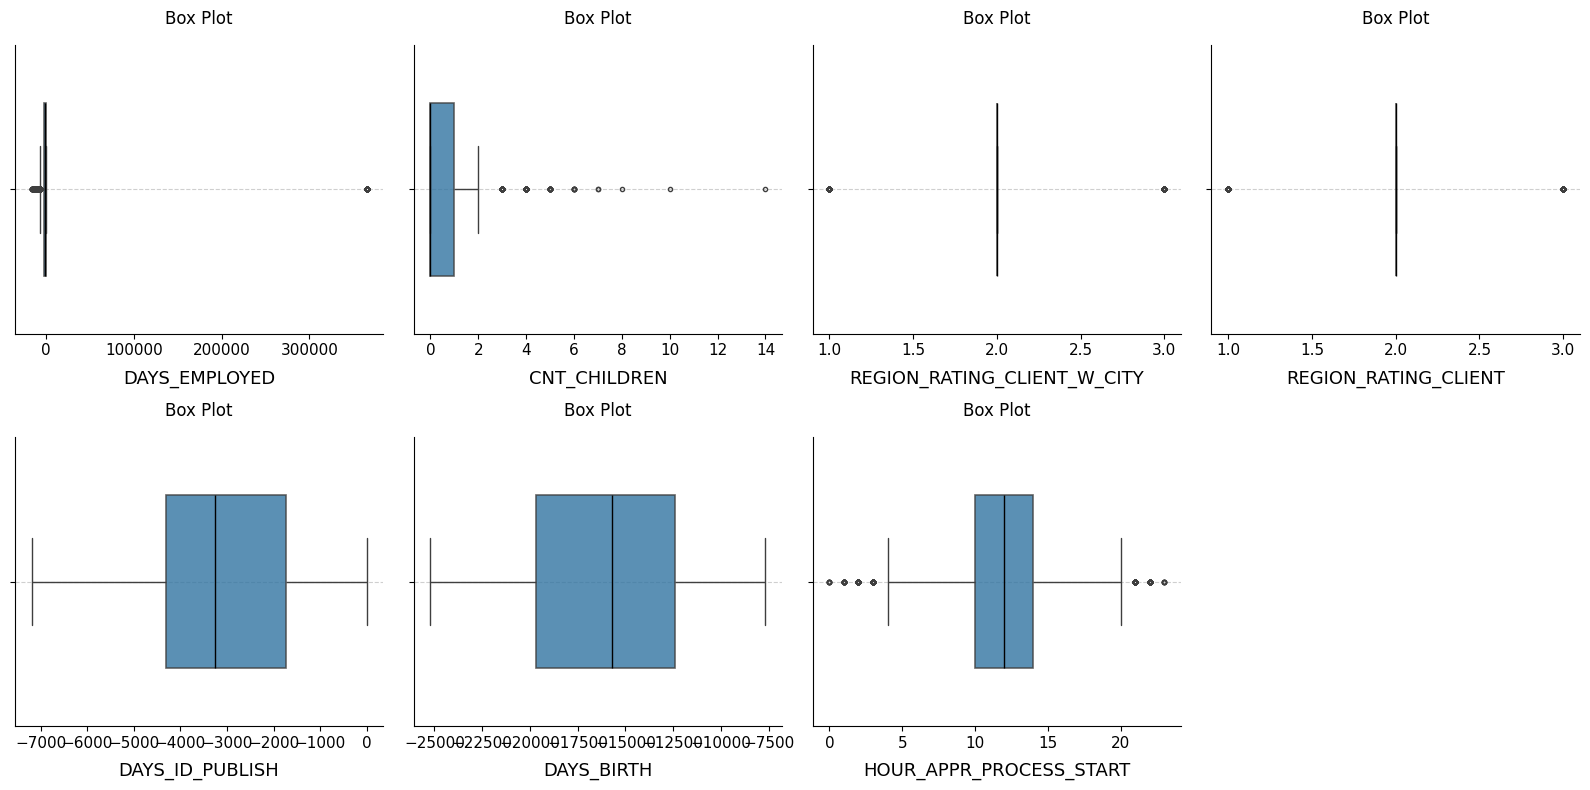

In [21]:
# kiểm tra outliers của các cột không phải nhị phân
boxplotter = BoxPlot(application_train_int64_nonbinary_column)
x_axis_list = nonbinary_cols
y_axis_list=[None for _ in range(len(nonbinary_cols))]
hue_list = [None for _ in range(len(nonbinary_cols))]

fig, axes = boxplotter.multiple_plots(y_axis_list=y_axis_list, plots_each_row=4,
                      x_axis_list=x_axis_list, hue_list=hue_list, readable_label=False, 
                                   kwarg={})

Có một vài cột có outlier, tuy nhiên mức độ outliers không quá nghiêm trọng, trong đó có 2 cột chỉ chứa 3 giá trị nên các điểm bên ngoài boxplot không bị xem là outliers, các cột còn lại có thể xử lý outliers bằng normalisation và standardise

In [22]:
# kiểm tra giá trị ngoại lại cho các cột là có dtype là float64
application_train_float64 = application_train_filtered.select_dtypes(include=['float64'])
application_train_float64.head()

,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_REGISTRATION,CNT_FAM_MEMBERS,EXT_SOURCE_2,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE
0,144000.0,264888.0,26329.5,234000.0,0.018850,-2684.0,3.0,0.687788,2.0,0.0,2.0,0.0,-1740.0
1,270000.0,679500.0,45724.5,679500.0,0.030755,-9211.0,2.0,0.609973,3.0,0.0,3.0,0.0,-369.0
2,202500.0,239850.0,22671.0,225000.0,0.009175,-2278.0,1.0,0.724092,0.0,0.0,0.0,0.0,-158.0
3,90000.0,454500.0,24345.0,454500.0,0.024610,-8244.0,1.0,0.708632,2.0,0.0,2.0,0.0,-540.0
4,189000.0,590337.0,28530.0,477000.0,0.004960,-2828.0,2.0,0.521348,0.0,0.0,0.0,0.0,-1562.0


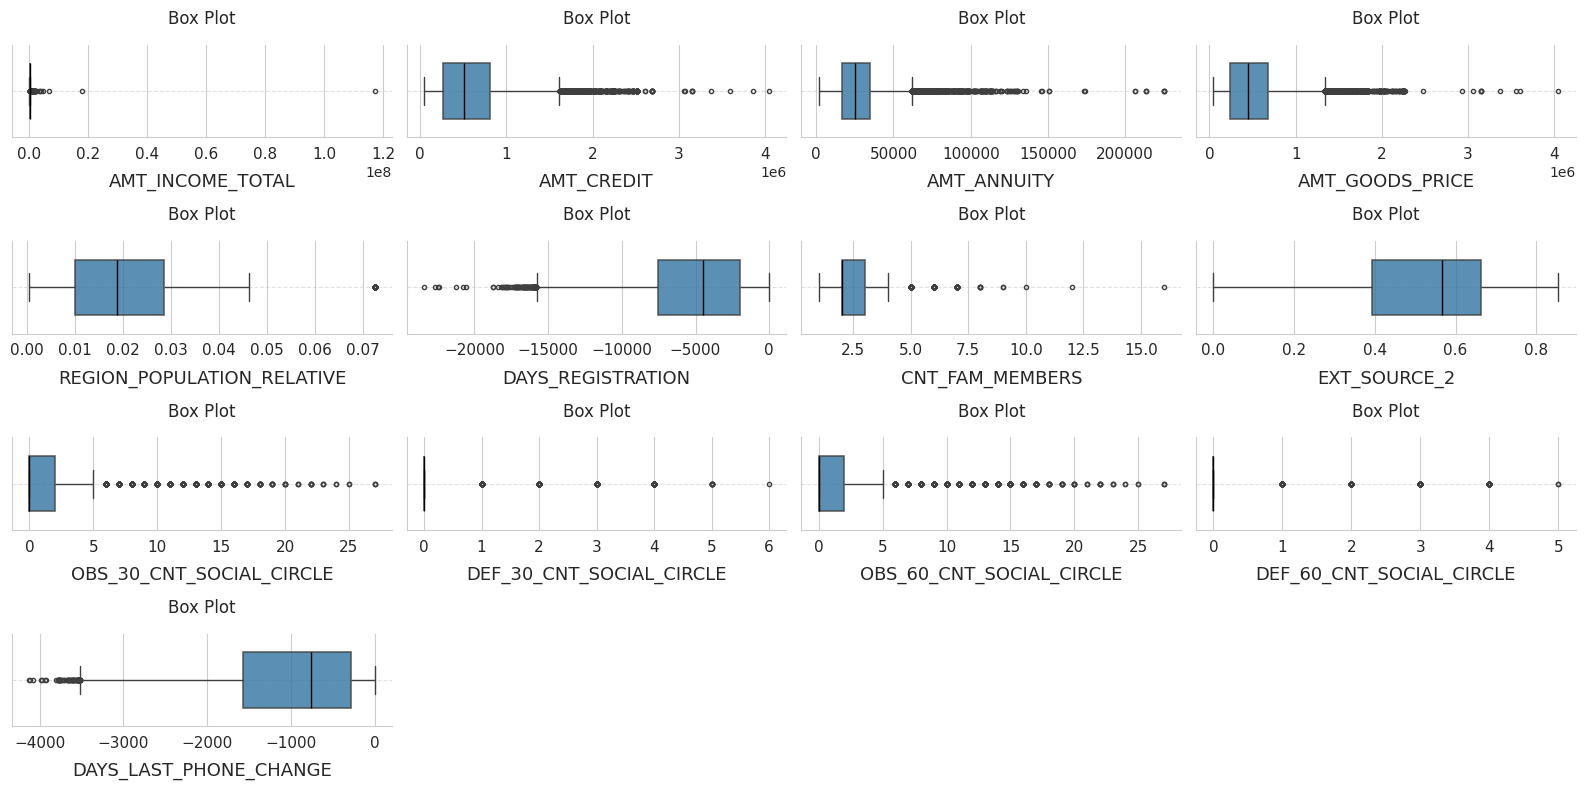

In [23]:
# kiểm tra outliers của các cột số thực
boxplotter = BoxPlot(application_train_float64)
all_columns = list(application_train_float64.columns)

x_axis_list = all_columns
y_axis_list=[None for _ in range(len(all_columns))]
hue_list = [None for _ in range(len(all_columns))]

fig, axes = boxplotter.multiple_plots(y_axis_list=y_axis_list, plots_each_row=4,
                      x_axis_list=x_axis_list, hue_list=hue_list, readable_label=False, 
                                   kwarg={})

Có 2 cột DEF là có số lượng giá trị không nhiều nên các điểm ngoài boxplot không được xem là outliers

Các cột còn lại thì có một số cột có nhiều outliers -> có thể xử lý bằng normalisation, lấy log hoặc dùng model Tree vì các model này robust với outliers

## Cho bureau

In [24]:
bureau_filtered.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 293655 entries, 0 to 293654
Data columns (total 12 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   SK_ID_CURR              293655 non-null  int64  
 1   SK_ID_BUREAU            293655 non-null  int64  
 2   CREDIT_ACTIVE           293655 non-null  object 
 3   CREDIT_CURRENCY         293655 non-null  object 
 4   DAYS_CREDIT             293655 non-null  int64  
 5   CREDIT_DAY_OVERDUE      293655 non-null  int64  
 6   DAYS_CREDIT_ENDDATE     275765 non-null  float64
 7   CNT_CREDIT_PROLONG      293655 non-null  int64  
 8   AMT_CREDIT_SUM          293652 non-null  float64
 9   AMT_CREDIT_SUM_OVERDUE  293655 non-null  float64
 10  CREDIT_TYPE             293655 non-null  object 
 11  DAYS_CREDIT_UPDATE      293655 non-null  int64  
dtypes: float64(3), int64(6), object(3)
memory usage: 26.9+ MB


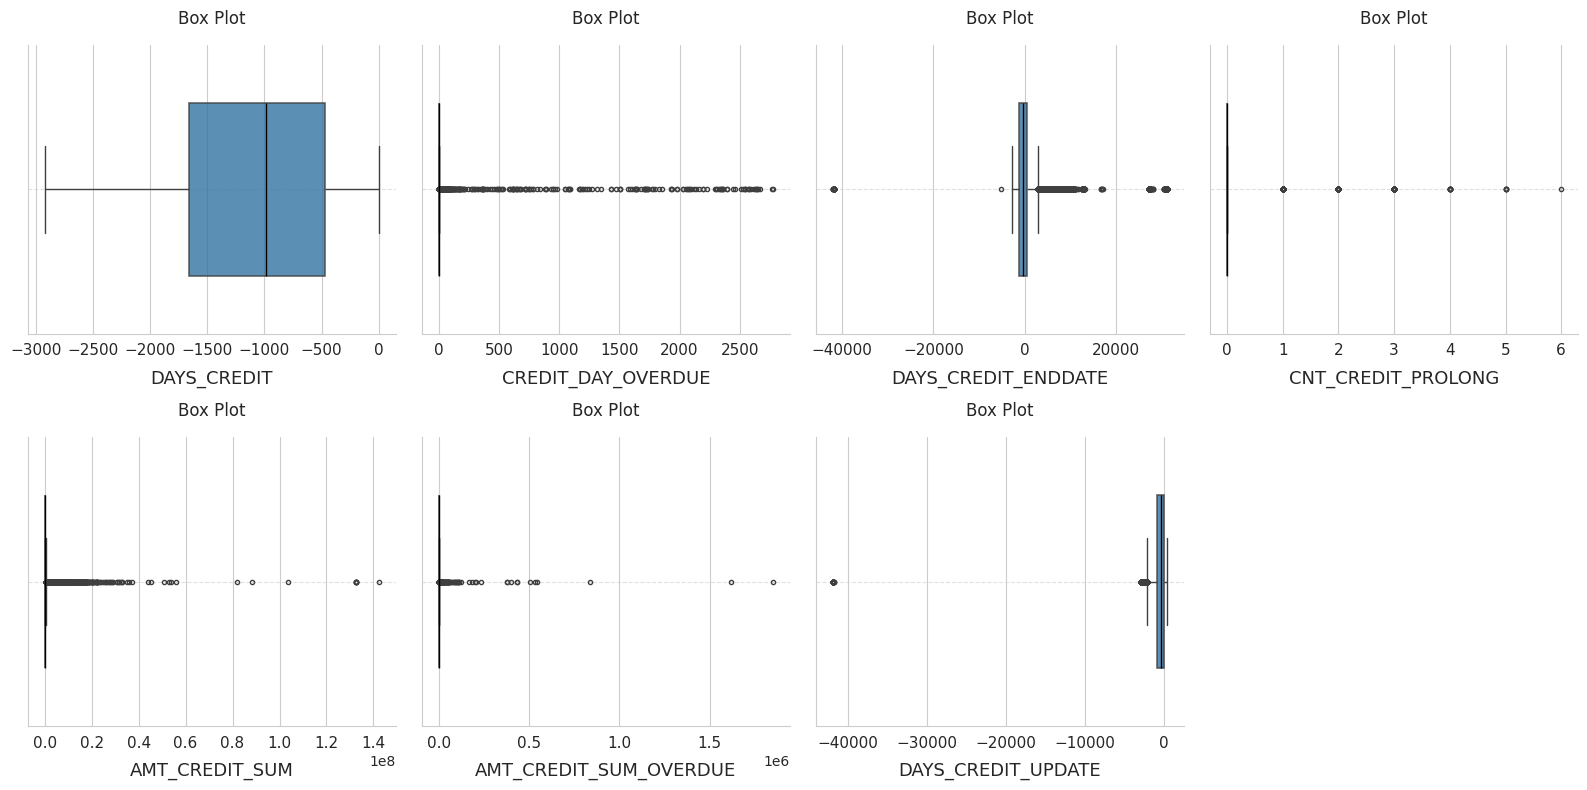

In [25]:
bureau_int_float = bureau_filtered.select_dtypes(include=['int64', 'float64'])
bureau_int_float = bureau_int_float.drop(columns=['SK_ID_CURR', 'SK_ID_BUREAU'])
# kiểm tra outliers của các cột
boxplotter = BoxPlot(bureau_int_float)
all_columns = list(bureau_int_float.columns)

x_axis_list = all_columns
y_axis_list=[None for _ in range(len(all_columns))]
hue_list = [None for _ in range(len(all_columns))]

fig, axes = boxplotter.multiple_plots(y_axis_list=y_axis_list, plots_each_row=4,
                      x_axis_list=x_axis_list, hue_list=hue_list, readable_label=False, 
                                   kwarg={})

Có một cột không bị xem là có outliers

Có vài cột có số lượng outlier rất lớn, một số outliers có thể bị loại bỏ đi hoặc áp dụng chuẩn hoá

## Cho bureau_balance

In [26]:
bureau_balance.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2968371 entries, 0 to 2968370
Data columns (total 3 columns):
 #   Column          Dtype 
---  ------          ----- 
 0   SK_ID_BUREAU    int64 
 1   MONTHS_BALANCE  int64 
 2   STATUS          object
dtypes: int64(2), object(1)
memory usage: 67.9+ MB


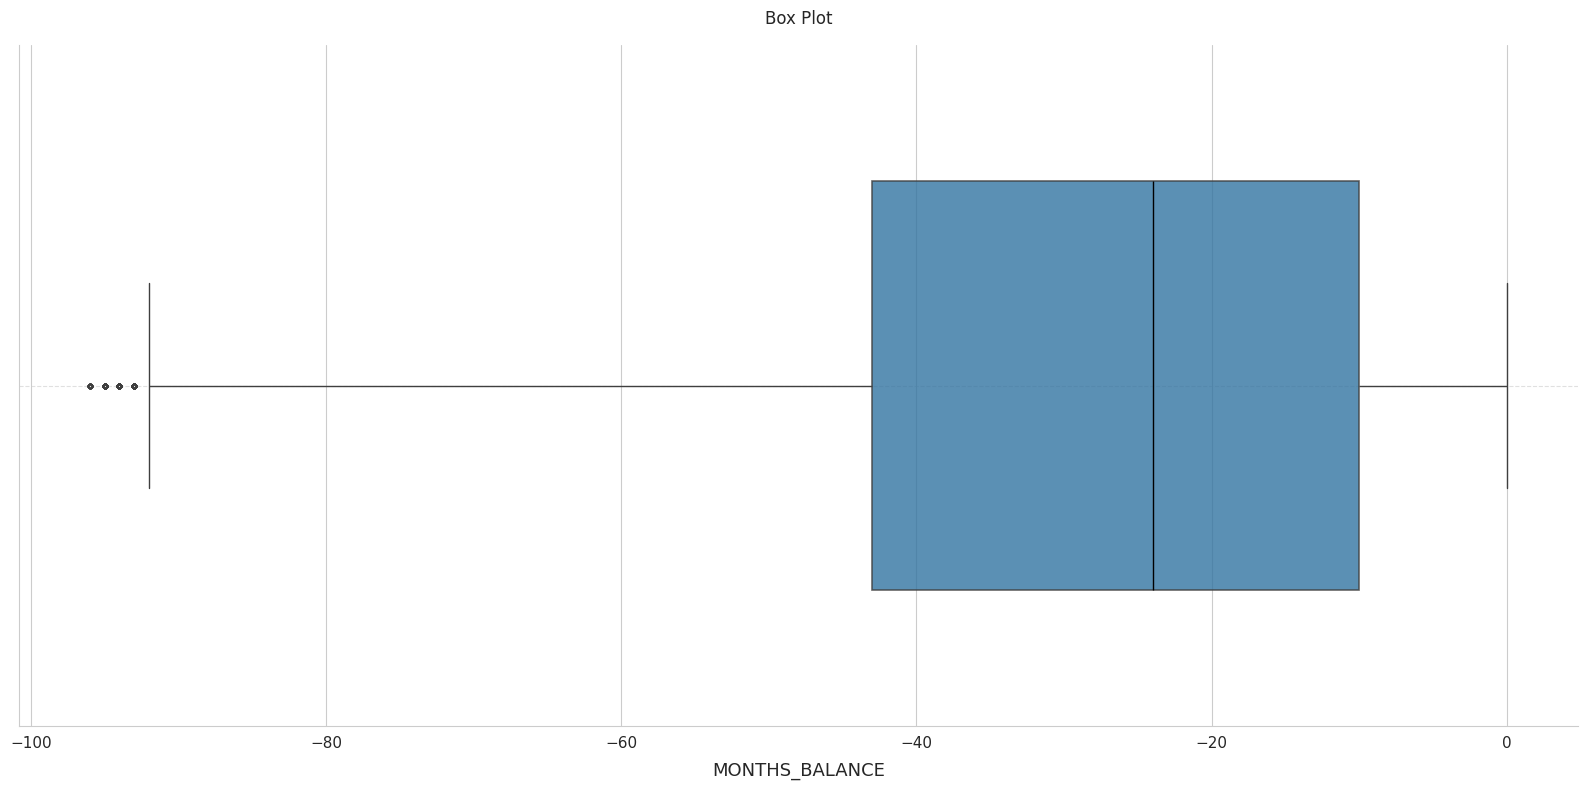

In [27]:
# kiểm tra outliers của các cột
boxplotter = BoxPlot(bureau_balance)

x_axis_list = ['MONTHS_BALANCE']
y_axis_list=[None for _ in range(1)]
hue_list = [None for _ in range(1)]

fig, axes = boxplotter.multiple_plots(y_axis_list=y_axis_list, plots_each_row=1,
                      x_axis_list=x_axis_list, hue_list=hue_list, readable_label=False, 
                                   kwarg={})

Có ít outliers

## Cho credit_card_balance

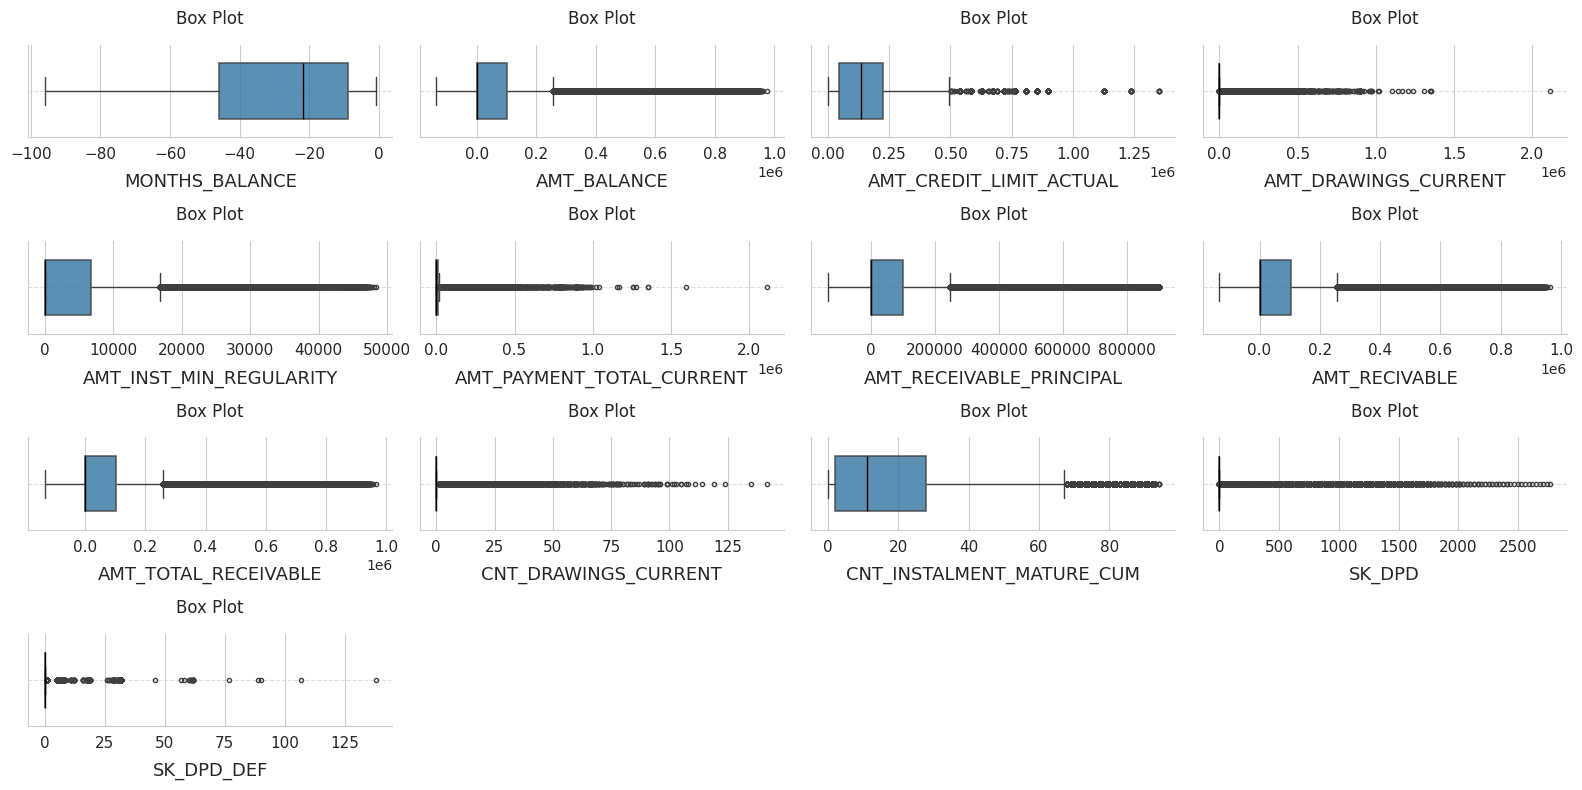

In [28]:
credit_card_balance_int_float = credit_card_balance_filtered.select_dtypes(include=['int64', 'float64'])
credit_card_balance_int_float = credit_card_balance_int_float.drop(columns=['SK_ID_CURR', 'SK_ID_PREV'])
all_columns = list(credit_card_balance_int_float.columns)

# kiểm tra outliers của các cột
boxplotter = BoxPlot(credit_card_balance_int_float)

x_axis_list = all_columns
y_axis_list=[None for _ in range(len(all_columns))]
hue_list = [None for _ in range(len(all_columns))]

fig, axes = boxplotter.multiple_plots(y_axis_list=y_axis_list, plots_each_row=4,
                      x_axis_list=x_axis_list, hue_list=hue_list, readable_label=False, 
                                   kwarg={})

Rất nhiều outliers

## Cho installments_payments

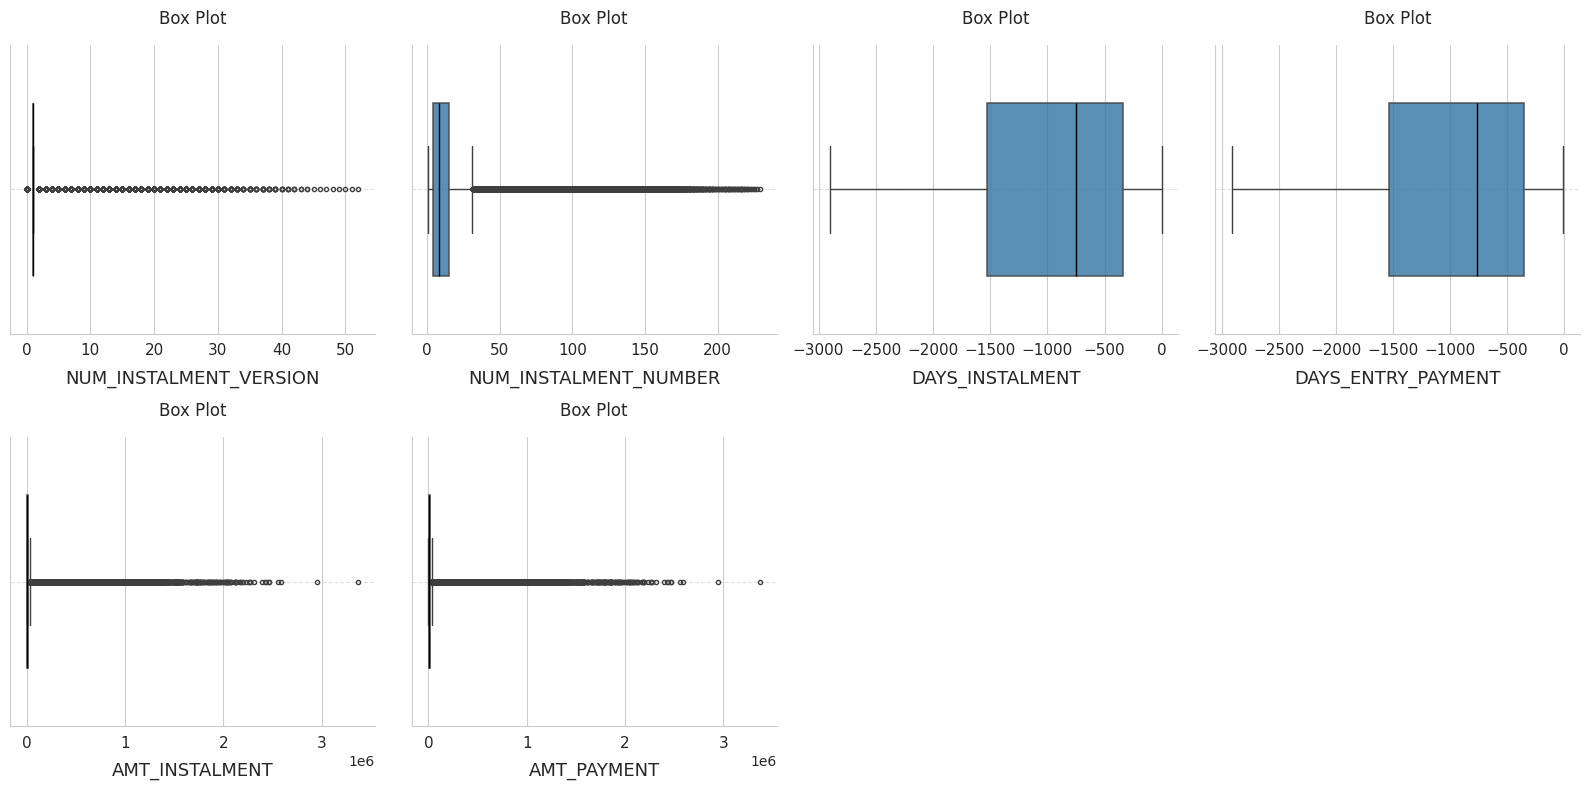

In [29]:
installments_payments_float_int = installments_payments_filtered.drop(columns=['SK_ID_PREV', 'SK_ID_CURR'])
all_columns = list(installments_payments_float_int.columns)

# kiểm tra outliers của các cột
boxplotter = BoxPlot(installments_payments_float_int)

x_axis_list = all_columns
y_axis_list=[None for _ in range(len(all_columns))]
hue_list = [None for _ in range(len(all_columns))]

fig, axes = boxplotter.multiple_plots(y_axis_list=y_axis_list, plots_each_row=4,
                      x_axis_list=x_axis_list, hue_list=hue_list, readable_label=False, 
                                   kwarg={})

Rất nhiều outliers

## Cho previous_application

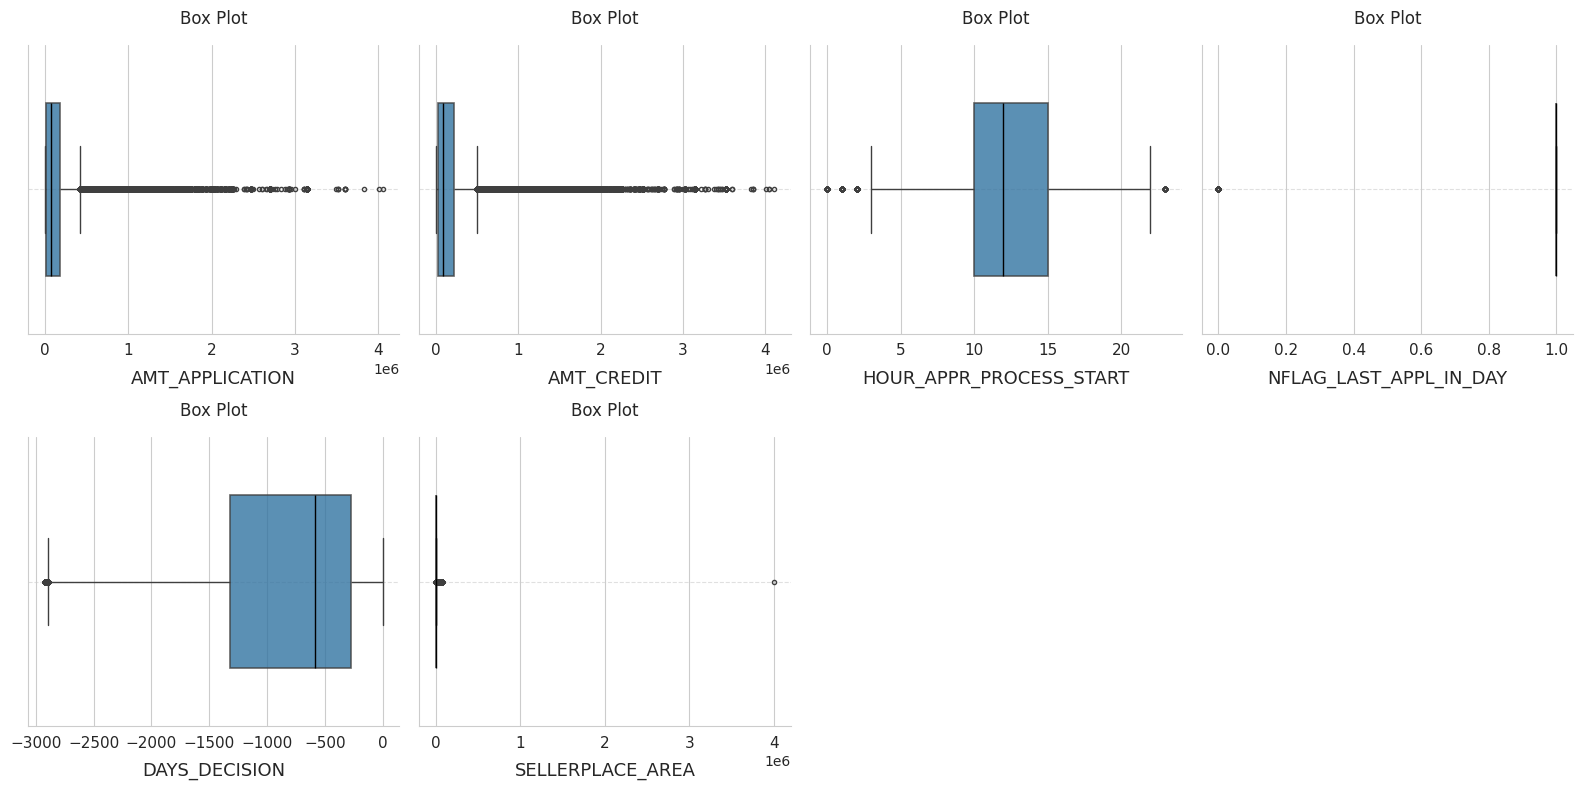

In [30]:
# kiểm tra giá trị ngoại lại cho các cột là có dtype là int64
previous_application_int_float = previous_application_filtered.select_dtypes(include=['int64', 'float64'])
previous_application_int_float = previous_application_int_float.drop(columns=['SK_ID_CURR', 'SK_ID_PREV'])

all_columns = list(previous_application_int_float.columns)

# kiểm tra outliers của các cột
boxplotter = BoxPlot(previous_application_int_float)

x_axis_list = all_columns
y_axis_list=[None for _ in range(len(all_columns))]
hue_list = [None for _ in range(len(all_columns))]

fig, axes = boxplotter.multiple_plots(y_axis_list=y_axis_list, plots_each_row=4,
                      x_axis_list=x_axis_list, hue_list=hue_list, readable_label=False, 
                                   kwarg={})

Có một cột dạng nhị phân, các cột còn lại có kha khá outliers

## Cho POS_CASH_balance

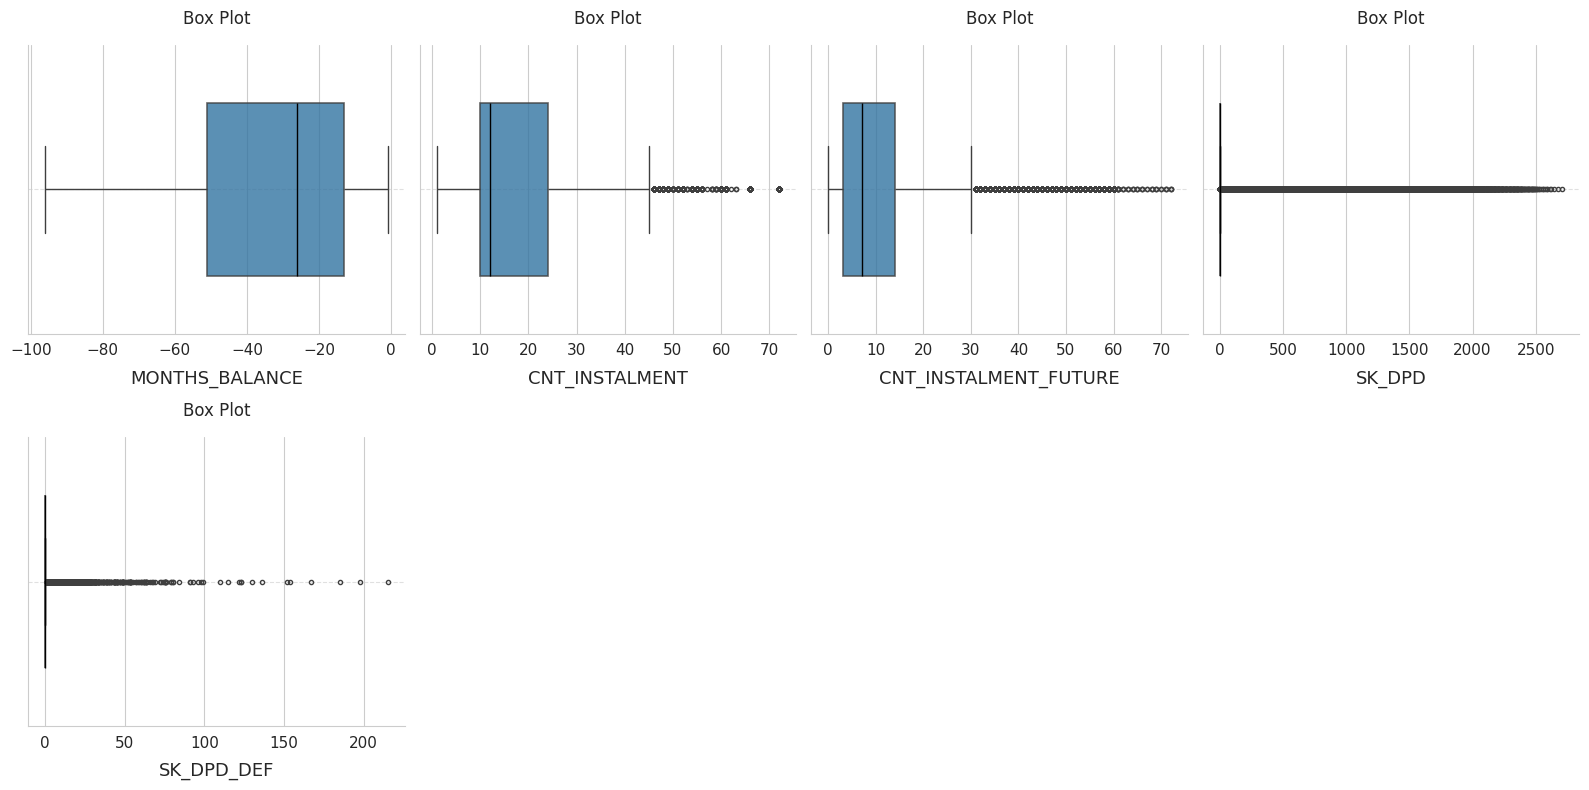

In [31]:
# kiểm tra giá trị ngoại lại cho các cột là có dtype là int64
POS_CASH_balance_int_float = POS_CASH_balance_filtered.select_dtypes(include=['int64', 'float64'])
POS_CASH_balance_int_float = POS_CASH_balance_int_float.drop(columns=['SK_ID_CURR', 'SK_ID_PREV'])

all_columns = list(POS_CASH_balance_int_float.columns)

# kiểm tra outliers của các cột
boxplotter = BoxPlot(POS_CASH_balance_int_float)

x_axis_list = all_columns
y_axis_list=[None for _ in range(len(all_columns))]
hue_list = [None for _ in range(len(all_columns))]

fig, axes = boxplotter.multiple_plots(y_axis_list=y_axis_list, plots_each_row=4,
                      x_axis_list=x_axis_list, hue_list=hue_list, readable_label=False, 
                                   kwarg={})

Có rất nhiều outliers

# Lưu dữ liệu

In [42]:
application_train_filtered.to_csv('application_train_filtered.csv')
bureau_filtered.to_csv('bureau_filtered.csv')
bureau_balance.to_csv('bureau_balance_filtered.csv')
credit_card_balance_filtered.to_csv('credit_card_balance_filtered.csv')
installments_payments_filtered.to_csv('installments_payments_filtered.csv')
previous_application_filtered.to_csv('previous_application_filtered.csv')
POS_CASH_balance_filtered.to_csv('POS_CASH_balance_filtered.csv')